# 🎬 IMDb Top 1000 — Análise Exploratória de Dados (EDA)

Este notebook realiza uma análise exploratória do dataset **IMDb Top 1000 Movies and TV Shows** (Kaggle) com foco em:
- qualidade percebida (**IMDb Rating**)
- crítica (**Metascore**)
- popularidade (**nº de votos**)
- desempenho financeiro (**Gross**)
- segmentação por **gênero**, **década**, **diretor** e **elenco**

---



## 1) Perguntas de análise

- Quais são os títulos **mais bem avaliados**, **mais votados** e **mais lucrativos**?
- Existe relação entre **duração** e **nota IMDb**?
- Existe relação entre **receita** e **nota IMDb**?
- Quais **gêneros** têm maior média de nota e quais tendem a maior receita?
- Como a **nota média** varia por **década**?
- **Diretores** e **atores** recorrentes mantêm desempenho consistente?
- **Crítica (Metascore)** e **público (IMDb)** se alinham?

---


In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 200)


In [3]:
import kagglehub

# Download da versão mais recente do dataset (KaggleHub)
path = kagglehub.dataset_download("harshitshankhdhar/imdb-dataset-of-top-1000-movies-and-tv-shows")
print("Path to dataset files:", path)

# Encontrar automaticamente o(s) CSV(s)
csv_files = [f for f in os.listdir(path) if f.lower().endswith(".csv")]
if not csv_files:
    raise FileNotFoundError("Nenhum arquivo .csv encontrado no diretório retornado pelo kagglehub.")

# Se houver mais de um CSV, escolhemos o primeiro por padrão
csv_path = os.path.join(path, csv_files[0])
print("CSV selecionado:", csv_path)


Path to dataset files: C:\Users\loren\.cache\kagglehub\datasets\harshitshankhdhar\imdb-dataset-of-top-1000-movies-and-tv-shows\versions\1
CSV selecionado: C:\Users\loren\.cache\kagglehub\datasets\harshitshankhdhar\imdb-dataset-of-top-1000-movies-and-tv-shows\versions\1\imdb_top_1000.csv


In [4]:
df = pd.read_csv(csv_path)
df.head(5)


,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross
0,https://m.media-amazon.com/images/M/MV5BMDFkYT...,The Shawshank Redemption,1994,A,142 min,Drama,9.3,Two imprisoned men bond over a number of years...,80.0,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,2343110,"28,341,469"
1,https://m.media-amazon.com/images/M/MV5BM2MyNj...,The Godfather,1972,A,175 min,"Crime, Drama",9.2,An organized crime dynasty's aging patriarch t...,100.0,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,1620367,"134,966,411"
2,https://m.media-amazon.com/images/M/MV5BMTMxNT...,The Dark Knight,2008,UA,152 min,"Action, Crime, Drama",9.0,When the menace known as the Joker wreaks havo...,84.0,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,2303232,"534,858,444"
3,https://m.media-amazon.com/images/M/MV5BMWMwMG...,The Godfather: Part II,1974,A,202 min,"Crime, Drama",9.0,The early life and career of Vito Corleone in ...,90.0,Francis Ford Coppola,Al Pacino,Robert De Niro,Robert Duvall,Diane Keaton,1129952,"57,300,000"
4,https://m.media-amazon.com/images/M/MV5BMWU4N2...,12 Angry Men,1957,U,96 min,"Crime, Drama",9.0,A jury holdout attempts to prevent a miscarria...,96.0,Sidney Lumet,Henry Fonda,Lee J. Cobb,Martin Balsam,John Fiedler,689845,"4,360,000"


## 2) Auditoria inicial (qualidade dos dados)

Checamos:
- dimensão (linhas/colunas)
- tipos de dados
- valores ausentes
- duplicatas

---


In [5]:
print("Shape:", df.shape)
display(df.sample(5, random_state=42))
df.info()


Shape: (1000, 16)


,Poster_Link,Series_Title,Released_Year,Certificate,Runtime,Genre,IMDB_Rating,Overview,Meta_score,Director,Star1,Star2,Star3,Star4,No_of_Votes,Gross
521,https://m.media-amazon.com/images/M/MV5BMjg5OG...,Trois couleurs: Bleu,1993,U,94 min,"Drama, Music, Mystery",7.9,A woman struggles to find a way to live her li...,85.0,Krzysztof Kieslowski,Juliette Binoche,Zbigniew Zamachowski,Julie Delpy,Benoît Régent,89836,"1,324,974"
737,https://m.media-amazon.com/images/M/MV5BMzA2ND...,Captain America: The Winter Soldier,2014,UA,136 min,"Action, Adventure, Sci-Fi",7.7,As Steve Rogers struggles to embrace his role ...,70.0,Anthony Russo,Joe Russo,Chris Evans,Samuel L. Jackson,Scarlett Johansson,736182,"259,766,572"
740,https://m.media-amazon.com/images/M/MV5BNzMxNT...,Wreck-It Ralph,2012,U,101 min,"Animation, Adventure, Comedy",7.7,A video game villain wants to be a hero and se...,72.0,Rich Moore,John C. Reilly,Jack McBrayer,Jane Lynch,Sarah Silverman,380195,"189,422,889"
660,https://m.media-amazon.com/images/M/MV5BODllYj...,The Sandlot,1993,U,101 min,"Comedy, Drama, Family",7.8,"In the summer of 1962, a new kid in town is ta...",55.0,David Mickey Evans,Tom Guiry,Mike Vitar,Art LaFleur,Patrick Renna,78963,"32,416,586"
411,https://m.media-amazon.com/images/M/MV5BMzJiZD...,Gandhi,1982,U,191 min,"Biography, Drama, History",8.0,The life of the lawyer who became the famed le...,79.0,Richard Attenborough,Ben Kingsley,John Gielgud,Rohini Hattangadi,Roshan Seth,217664,"52,767,889"


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Poster_Link    1000 non-null   object 
 1   Series_Title   1000 non-null   object 
 2   Released_Year  1000 non-null   object 
 3   Certificate    899 non-null    object 
 4   Runtime        1000 non-null   object 
 5   Genre          1000 non-null   object 
 6   IMDB_Rating    1000 non-null   float64
 7   Overview       1000 non-null   object 
 8   Meta_score     843 non-null    float64
 9   Director       1000 non-null   object 
 10  Star1          1000 non-null   object 
 11  Star2          1000 non-null   object 
 12  Star3          1000 non-null   object 
 13  Star4          1000 non-null   object 
 14  No_of_Votes    1000 non-null   int64  
 15  Gross          831 non-null    object 
dtypes: float64(2), int64(1), object(13)
memory usage: 125.1+ KB


In [6]:
null_count = df.isna().sum().sort_values(ascending=False)
null_rate = (df.isna().mean() * 100).sort_values(ascending=False)

nulls = (
    pd.DataFrame({"null_count": null_count, "null_%": null_rate})
      .query("null_count > 0")
)
nulls


,null_count,null_%
Gross,169,16.9
Meta_score,157,15.7
Certificate,101,10.1


## 3) Padronização e limpeza

- Padronizamos nomes das colunas (snake_case)
- Tipamos colunas numéricas com segurança
- Tratamos campos essenciais (ex.: `imdb_rating`)
- Mantemos `gross` nulo quando ausente (não imputamos receita)

---


In [7]:
df.columns = (
    df.columns
      .str.strip()
      .str.lower()
      .str.replace(" ", "_")
)

df.columns.tolist()


['poster_link',
 'series_title',
 'released_year',
 'certificate',
 'runtime',
 'genre',
 'imdb_rating',
 'overview',
 'meta_score',
 'director',
 'star1',
 'star2',
 'star3',
 'star4',
 'no_of_votes',
 'gross']

In [8]:
def to_float_gross(x):
    """Converte valores de 'gross' (string com vírgulas) para float; retorna NaN se falhar."""
    if pd.isna(x):
        return np.nan
    x = str(x).strip().replace(",", "")
    try:
        return float(x)
    except ValueError:
        return np.nan

def to_int_runtime(x):
    """Converte 'runtime' tipo '142 min' -> 142; retorna NaN se falhar."""
    if pd.isna(x):
        return np.nan
    x = str(x).strip().lower().replace("min", "").strip()
    try:
        return int(x)
    except ValueError:
        return np.nan

# certificate: preencher nulos
if "certificate" in df.columns:
    df["certificate"] = df["certificate"].fillna("Not Rated")

# Tipagem numérica segura
for col in ["released_year", "imdb_rating", "meta_score", "no_of_votes"]:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

# gross pode vir como string com vírgulas; convertemos se necessário
if "gross" in df.columns and not pd.api.types.is_numeric_dtype(df["gross"]):
    df["gross"] = df["gross"].apply(to_float_gross)
else:
    # se já for numérico, apenas garante coerção
    if "gross" in df.columns:
        df["gross"] = pd.to_numeric(df["gross"], errors="coerce")

# runtime_min: só cria se não existir
if "runtime_min" not in df.columns and "runtime" in df.columns:
    df["runtime_min"] = df["runtime"].apply(to_int_runtime)

# Remover linhas sem nota (campo essencial)
df = df.dropna(subset=["imdb_rating"])

print("Shape após limpeza básica:", df.shape)
df.head(3)


Shape após limpeza básica: (1000, 17)


,poster_link,series_title,released_year,certificate,runtime,genre,imdb_rating,overview,meta_score,director,star1,star2,star3,star4,no_of_votes,gross,runtime_min
0,https://m.media-amazon.com/images/M/MV5BMDFkYT...,The Shawshank Redemption,1994.0,A,142 min,Drama,9.3,Two imprisoned men bond over a number of years...,80.0,Frank Darabont,Tim Robbins,Morgan Freeman,Bob Gunton,William Sadler,2343110,28341469.0,142
1,https://m.media-amazon.com/images/M/MV5BM2MyNj...,The Godfather,1972.0,A,175 min,"Crime, Drama",9.2,An organized crime dynasty's aging patriarch t...,100.0,Francis Ford Coppola,Marlon Brando,Al Pacino,James Caan,Diane Keaton,1620367,134966411.0,175
2,https://m.media-amazon.com/images/M/MV5BMTMxNT...,The Dark Knight,2008.0,UA,152 min,"Action, Crime, Drama",9.0,When the menace known as the Joker wreaks havo...,84.0,Christopher Nolan,Christian Bale,Heath Ledger,Aaron Eckhart,Michael Caine,2303232,534858444.0,152


In [9]:
# Duplicatas (linhas)
print("Duplicatas (linhas inteiras):", df.duplicated().sum())

# Duplicatas por título (mais relevante)
if "series_title" in df.columns:
    print("Duplicatas por series_title:", df.duplicated(subset=["series_title"]).sum())


Duplicatas (linhas inteiras): 0
Duplicatas por series_title: 1


## 4) Feature engineering

- `decade`: década de lançamento
- `gross_musd`: receita em milhões USD (facilita leitura)
- `genre_list` + `df_genre`: explode de gênero (um título pode ter múltiplos)

---


In [10]:
df["decade"] = (df["released_year"] // 10) * 10
df["gross_musd"] = df["gross"] / 1_000_000

df["genre_list"] = df["genre"].fillna("").str.split(", ")
df_genre = df.explode("genre_list")
df_genre = df_genre[df_genre["genre_list"].ne("")]

df[["series_title", "released_year", "decade", "imdb_rating", "meta_score", "no_of_votes", "gross_musd"]].head()


,series_title,released_year,decade,imdb_rating,meta_score,no_of_votes,gross_musd
0,The Shawshank Redemption,1994.0,1990.0,9.3,80.0,2343110,28.341469
1,The Godfather,1972.0,1970.0,9.2,100.0,1620367,134.966411
2,The Dark Knight,2008.0,2000.0,9.0,84.0,2303232,534.858444
3,The Godfather: Part II,1974.0,1970.0,9.0,90.0,1129952,57.300000
4,12 Angry Men,1957.0,1950.0,9.0,96.0,689845,4.360000


## 5) Estatísticas descritivas

Visão geral das variáveis numéricas principais.

---


In [11]:
num_cols = [c for c in ["imdb_rating", "meta_score", "runtime_min", "no_of_votes", "gross_musd"] if c in df.columns]
df[num_cols].describe()


,imdb_rating,meta_score,runtime_min,no_of_votes,gross_musd
count,1000.000000,843.000000,1000.000000,1.000000e+03,831.000000
mean,7.949300,77.971530,122.891000,2.736929e+05,68.034751
std,0.275491,12.376099,28.093671,3.273727e+05,109.750043
min,7.600000,28.000000,45.000000,2.508800e+04,0.001305
25%,7.700000,70.000000,103.000000,5.552625e+04,3.253559
50%,7.900000,79.000000,119.000000,1.385485e+05,23.530892
75%,8.100000,87.000000,137.000000,3.741612e+05,80.750893
max,9.300000,100.000000,321.000000,2.343110e+06,936.662225


## 6) Distribuições

Entender a distribuição ajuda a identificar concentração, assimetria e outliers.

---


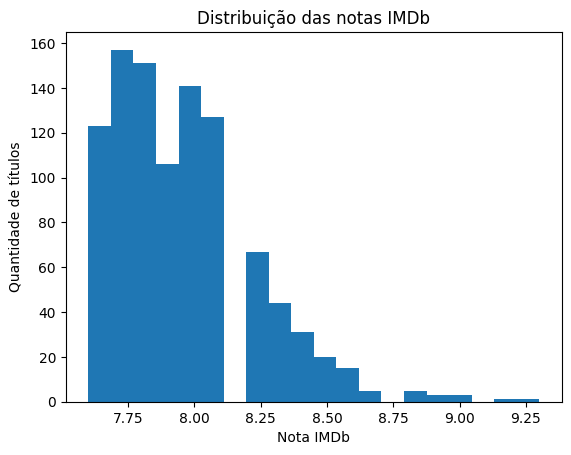

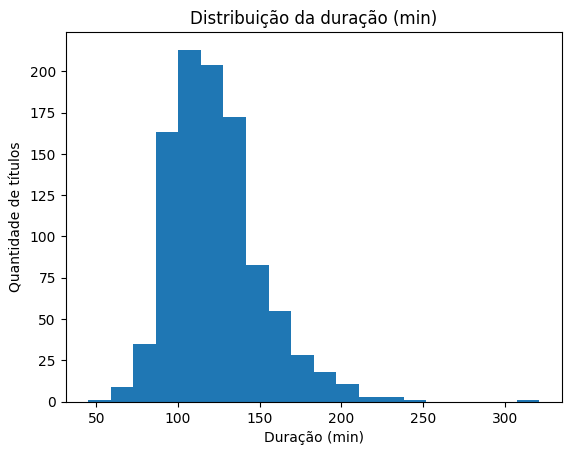

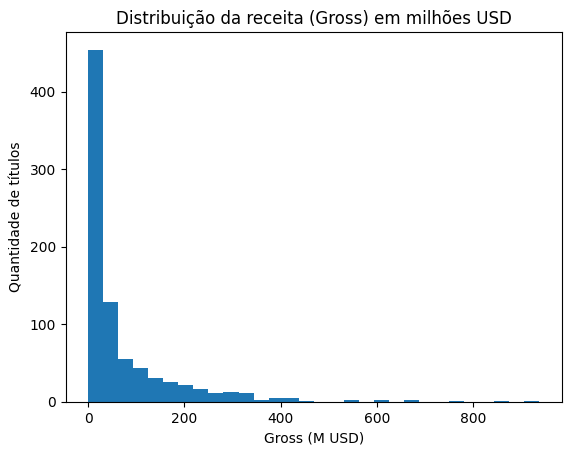

In [12]:
plt.figure()
plt.hist(df["imdb_rating"].dropna(), bins=20)
plt.title("Distribuição das notas IMDb")
plt.xlabel("Nota IMDb")
plt.ylabel("Quantidade de títulos")
plt.show()

plt.figure()
plt.hist(df["runtime_min"].dropna(), bins=20)
plt.title("Distribuição da duração (min)")
plt.xlabel("Duração (min)")
plt.ylabel("Quantidade de títulos")
plt.show()

plt.figure()
plt.hist(df["gross_musd"].dropna(), bins=30)
plt.title("Distribuição da receita (Gross) em milhões USD")
plt.xlabel("Gross (M USD)")
plt.ylabel("Quantidade de títulos")
plt.show()


## 7) Rankings (Top títulos)

---


In [13]:
cols = [c for c in ["series_title", "imdb_rating", "released_year", "genre", "runtime_min"] if c in df.columns]
top_rated = df.sort_values("imdb_rating", ascending=False).head(10)[cols]
top_rated


,series_title,imdb_rating,released_year,genre,runtime_min
0,The Shawshank Redemption,9.3,1994.0,Drama,142
1,The Godfather,9.2,1972.0,"Crime, Drama",175
2,The Dark Knight,9.0,2008.0,"Action, Crime, Drama",152
3,The Godfather: Part II,9.0,1974.0,"Crime, Drama",202
4,12 Angry Men,9.0,1957.0,"Crime, Drama",96
5,The Lord of the Rings: The Return of the King,8.9,2003.0,"Action, Adventure, Drama",201
6,Pulp Fiction,8.9,1994.0,"Crime, Drama",154
7,Schindler's List,8.9,1993.0,"Biography, Drama, History",195
8,Inception,8.8,2010.0,"Action, Adventure, Sci-Fi",148
9,Fight Club,8.8,1999.0,Drama,139


In [14]:
df_gross = df.dropna(subset=["gross_musd"]).copy()

cols_g = [c for c in ["series_title", "gross_musd", "imdb_rating", "no_of_votes", "released_year", "genre"] if c in df_gross.columns]
top_gross = df_gross.sort_values("gross_musd", ascending=False).head(10)[cols_g].copy()
top_gross["gross_musd"] = top_gross["gross_musd"].round(2)
top_gross


,series_title,gross_musd,imdb_rating,no_of_votes,released_year,genre
477,Star Wars: Episode VII - The Force Awakens,936.66,7.9,860823,2015.0,"Action, Adventure, Sci-Fi"
59,Avengers: Endgame,858.37,8.4,809955,2019.0,"Action, Adventure, Drama"
623,Avatar,760.51,7.8,1118998,2009.0,"Action, Adventure, Fantasy"
60,Avengers: Infinity War,678.82,8.4,834477,2018.0,"Action, Adventure, Sci-Fi"
652,Titanic,659.33,7.8,1046089,1997.0,"Drama, Romance"
357,The Avengers,623.28,8.0,1260806,2012.0,"Action, Adventure, Sci-Fi"
891,Incredibles 2,608.58,7.6,250057,2018.0,"Animation, Action, Adventure"
2,The Dark Knight,534.86,9.0,2303232,2008.0,"Action, Crime, Drama"
582,Rogue One,532.18,7.8,556608,2016.0,"Action, Adventure, Sci-Fi"
63,The Dark Knight Rises,448.14,8.4,1516346,2012.0,"Action, Adventure"


In [15]:
cols_v = [c for c in ["series_title", "no_of_votes", "imdb_rating", "released_year", "genre"] if c in df.columns]
df.sort_values("no_of_votes", ascending=False).head(10)[cols_v]


,series_title,no_of_votes,imdb_rating,released_year,genre
0,The Shawshank Redemption,2343110,9.3,1994.0,Drama
2,The Dark Knight,2303232,9.0,2008.0,"Action, Crime, Drama"
8,Inception,2067042,8.8,2010.0,"Action, Adventure, Sci-Fi"
9,Fight Club,1854740,8.8,1999.0,Drama
6,Pulp Fiction,1826188,8.9,1994.0,"Crime, Drama"
11,Forrest Gump,1809221,8.8,1994.0,"Drama, Romance"
14,The Matrix,1676426,8.7,1999.0,"Action, Sci-Fi"
10,The Lord of the Rings: The Fellowship of the Ring,1661481,8.8,2001.0,"Action, Adventure, Drama"
5,The Lord of the Rings: The Return of the King,1642758,8.9,2003.0,"Action, Adventure, Drama"
1,The Godfather,1620367,9.2,1972.0,"Crime, Drama"


## 8) Relações entre variáveis (correlação e dispersão)

Observação: correlação aqui tende a ser fraca — o valor está no insight (ex.: blockbusters vs qualidade percebida).

---


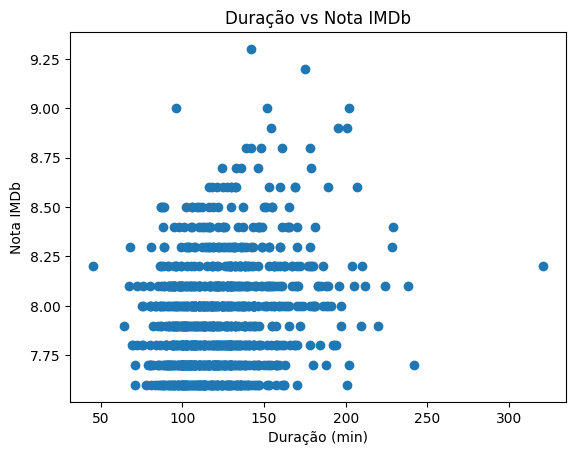

Correlação (runtime_min vs imdb_rating): 0.2431


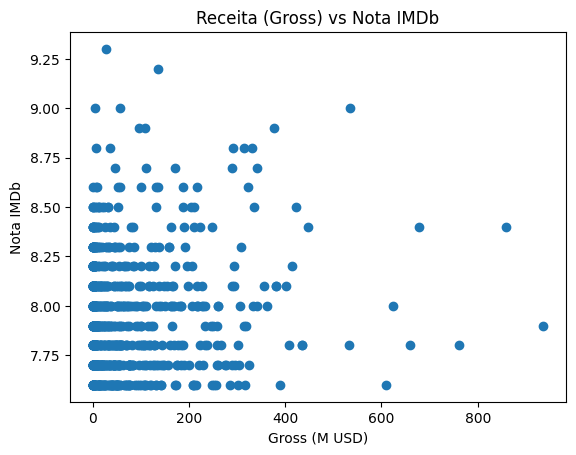

Correlação (gross_musd vs imdb_rating): 0.0959


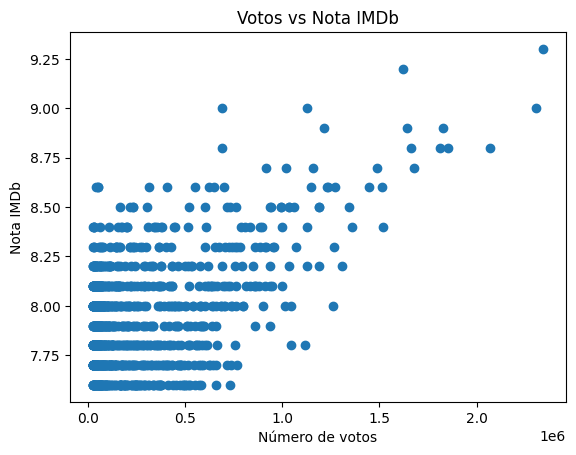

Correlação (no_of_votes vs imdb_rating): 0.495


In [16]:
# Duração vs Nota
plt.figure()
plt.scatter(df["runtime_min"], df["imdb_rating"])
plt.title("Duração vs Nota IMDb")
plt.xlabel("Duração (min)")
plt.ylabel("Nota IMDb")
plt.show()

corr_runtime = df[["runtime_min", "imdb_rating"]].dropna().corr().iloc[0, 1]
print("Correlação (runtime_min vs imdb_rating):", round(corr_runtime, 4))

# Receita vs Nota (apenas títulos com gross)
plt.figure()
plt.scatter(df_gross["gross_musd"], df_gross["imdb_rating"])
plt.title("Receita (Gross) vs Nota IMDb")
plt.xlabel("Gross (M USD)")
plt.ylabel("Nota IMDb")
plt.show()

corr_gross = df_gross[["gross_musd", "imdb_rating"]].dropna().corr().iloc[0, 1]
print("Correlação (gross_musd vs imdb_rating):", round(corr_gross, 4))

# Votos vs Nota
plt.figure()
plt.scatter(df["no_of_votes"], df["imdb_rating"])
plt.title("Votos vs Nota IMDb")
plt.xlabel("Número de votos")
plt.ylabel("Nota IMDb")
plt.show()

corr_votes = df[["no_of_votes", "imdb_rating"]].dropna().corr().iloc[0, 1]
print("Correlação (no_of_votes vs imdb_rating):", round(corr_votes, 4))


## 9) Análise temporal (décadas)

---


In [17]:
rating_decade = (
    df.dropna(subset=["decade"])
      .groupby("decade")["imdb_rating"]
      .agg(count="count", mean="mean")
      .sort_index()
)

rating_decade


,count,mean
decade,,
1920.0,11,8.127273
1930.0,24,7.966667
1940.0,35,8.025714
1950.0,56,8.058929
1960.0,73,7.973973
1970.0,76,7.969737
1980.0,89,7.953933
1990.0,150,7.963333
2000.0,237,7.899578


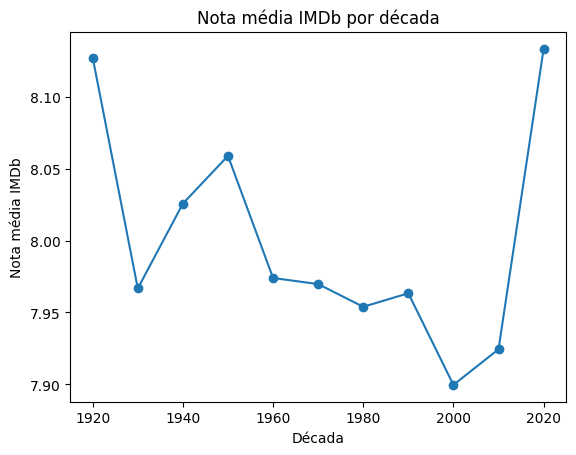

In [18]:
plt.figure()
plt.plot(rating_decade.index, rating_decade["mean"], marker="o")
plt.title("Nota média IMDb por década")
plt.xlabel("Década")
plt.ylabel("Nota média IMDb")
plt.show()


## 10) Análise por gênero

Usamos `explode` para permitir que um título conte em múltiplos gêneros.
Aplicamos filtro de amostra mínima para evitar ruído (`count >= 20`).

---


In [19]:
genre_rating = (
    df_genre.groupby("genre_list")["imdb_rating"]
            .agg(count="count", mean="mean")
            .sort_values("mean", ascending=False)
)

genre_rating_filtered = genre_rating.query("count >= 20").head(15)
genre_rating_filtered


,count,mean
genre_list,,
War,51,8.013725
Western,20,8.000000
Sci-Fi,67,7.977612
Mystery,99,7.967677
Drama,724,7.959392
Crime,209,7.954545
History,56,7.953571
Adventure,196,7.952041
Action,189,7.948677


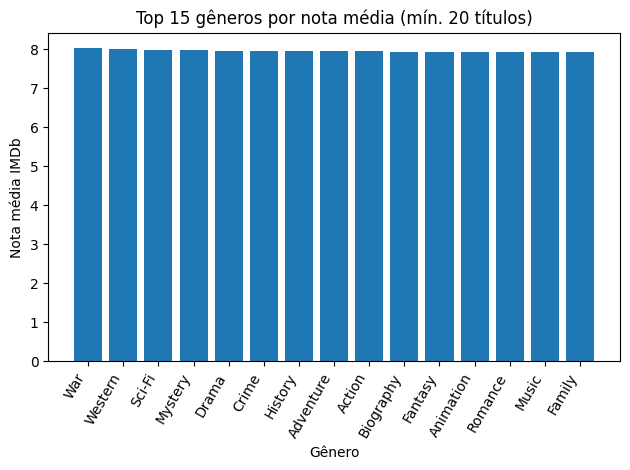

In [20]:
top15_genres = genre_rating.query("count >= 20").sort_values("mean", ascending=False).head(15)

plt.figure()
plt.bar(top15_genres.index, top15_genres["mean"])
plt.title("Top 15 gêneros por nota média (mín. 20 títulos)")
plt.xlabel("Gênero")
plt.ylabel("Nota média IMDb")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()


In [21]:
genre_gross = (
    df_genre.dropna(subset=["gross_musd"])
            .groupby("genre_list")["gross_musd"]
            .agg(count="count", mean="mean", median="median")
            .sort_values("mean", ascending=False)
)

genre_gross_filtered = genre_gross.query("count >= 20").head(15)
genre_gross_filtered


,count,mean,median
genre_list,,,
Adventure,170,165.731279,120.580487
Sci-Fi,61,148.026397,70.511035
Action,156,141.239283,65.707655
Animation,67,127.967528,75.082668
Fantasy,56,108.616842,45.953122
Family,48,92.932657,46.061332
Comedy,191,64.125296,18.600000
Thriller,110,58.676627,25.782912
History,43,55.539532,43.984230


## 11) Diretores (qualidade consistente)

Ranking por média de IMDb Rating com filtro de amostra mínima (`count >= 5`).

---


In [22]:
director_stats = (
    df.groupby("director")["imdb_rating"]
      .agg(count="count", mean="mean")
      .query("count >= 5")
      .sort_values("mean", ascending=False)
)

director_stats.head(15)


,count,mean
director,,
Christopher Nolan,8,8.462500
Francis Ford Coppola,5,8.400000
Peter Jackson,5,8.400000
Charles Chaplin,6,8.333333
Sergio Leone,6,8.266667
Stanley Kubrick,9,8.233333
Akira Kurosawa,10,8.220000
Quentin Tarantino,8,8.175000
Martin Scorsese,10,8.170000


## 12) Atores/estrelas

Consolidamos `star1..star4` em uma única coluna via `melt`.
Aplicamos filtro de amostra mínima (`count >= 5`).

---


In [23]:
stars = df.melt(
    id_vars=["imdb_rating"],
    value_vars=[c for c in ["star1", "star2", "star3", "star4"] if c in df.columns],
    value_name="star"
).dropna(subset=["star"])

star_stats = (
    stars.groupby("star")["imdb_rating"]
         .agg(count="count", mean="mean")
         .query("count >= 5")
         .sort_values("mean", ascending=False)
)

star_stats.head(15)


,count,mean
star,,
Charles Chaplin,6,8.333333
Kevin Spacey,5,8.300000
Harrison Ford,8,8.262500
Viggo Mortensen,5,8.260000
Tatsuya Nakadai,6,8.250000
Toshirô Mifune,7,8.242857
Aamir Khan,8,8.237500
Diane Keaton,6,8.233333
Ian McKellen,7,8.214286


## 13) Crítica vs Público (Metascore vs IMDb)

---


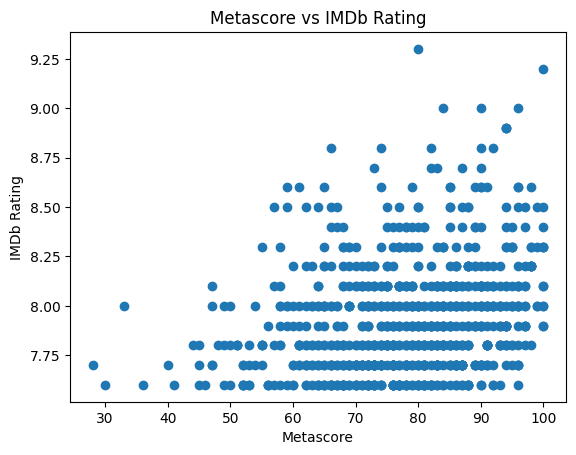

Correlação (meta_score vs imdb_rating): 0.2685


In [24]:
df_meta = df.dropna(subset=["meta_score"]).copy()

plt.figure()
plt.scatter(df_meta["meta_score"], df_meta["imdb_rating"])
plt.title("Metascore vs IMDb Rating")
plt.xlabel("Metascore")
plt.ylabel("IMDb Rating")
plt.show()

corr_meta = df_meta[["meta_score", "imdb_rating"]].corr().iloc[0, 1]
print("Correlação (meta_score vs imdb_rating):", round(corr_meta, 4))


## 14) Exportar gráficos para o repositório

Salvamos um gráfico principal em `../images/graficos.png` para uso no README.

---


In [25]:
OUT_DIR = "../images"
os.makedirs(OUT_DIR, exist_ok=True)

plt.figure()
plt.scatter(df["runtime_min"], df["imdb_rating"])
plt.title("Duração vs Nota IMDb")
plt.xlabel("Duração (min)")
plt.ylabel("Nota IMDb")
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, "graficos.png"))
plt.close()

print("Salvo em:", os.path.join(OUT_DIR, "graficos.png"))


Salvo em: ../images\graficos.png


## 🧾 Conclusões Finais

Esta análise exploratória investigou padrões de avaliação, popularidade, receita e características narrativas dos **1000 títulos mais bem avaliados do IMDb**, com o objetivo de compreender quais fatores estão associados à **qualidade percebida pelo público**.

---

### ⭐ Qualidade percebida (IMDb Rating)
- A **nota média do dataset é 7,95**, com valores variando entre **7,6 e 9,3**.
- O conjunto de dados é altamente selecionado, representando uma comparação entre **bons e excelentes títulos**, e não entre bons e ruins.

---

### ⏱️ Duração dos filmes
- A relação entre **duração (`runtime_min`) e avaliação IMDb é fraca**.
- Filmes mais longos apresentam, em média, **ligeiramente** notas mais altas, porém a duração **não é determinante da qualidade percebida**.

---

### 🗳️ Popularidade
- Observa-se uma **correlação moderada** entre **número de votos** e **nota IMDb**.
- Filmes mais populares tendem a ser melhor avaliados, mas **popularidade não garante excelência**, existindo títulos muito votados com avaliações medianas.

---

### 📰 Crítica especializada vs público
- A relação entre **Metascore (crítica)** e **IMDb Rating (público)** é **moderada**.
- Isso indica que crítica e público **concordam parcialmente**, mas utilizam critérios distintos de avaliação.

---

### 💰 Receita
- Não foi possível identificar uma relação consistente entre **receita bruta (`gross`)** e **avaliação IMDb**.
- A grande quantidade de valores ausentes limita conclusões nesse aspecto.
- Portanto, **sucesso financeiro não pode ser interpretado como sinônimo de qualidade** neste dataset.

---

### 🎭 Gêneros
- Gêneros como **War, Western, Sci-Fi, Mystery e Drama** apresentam as **maiores médias de avaliação**.
- Gêneros mais narrativos e reflexivos tendem a obter **melhor aceitação crítica e do público**, enquanto gêneros mais comerciais não lideram necessariamente em avaliação média.

---

### 🕰️ Análise temporal
- A década de **2020** apresentou a maior média de avaliação, porém com **amostra reduzida**, o que exige cautela na interpretação.
- Títulos recentes muito bem avaliados tendem a entrar rapidamente no Top 1000, mas isso **não implica superioridade sistemática** em relação a décadas anteriores.

---

### 🧠 Síntese Executiva
> A qualidade percebida no IMDb resulta de um **conjunto de fatores**, e não de um único elemento isolado.  
> Popularidade contribui, duração tem efeito marginal e sucesso financeiro não garante avaliação alta.  
> Gêneros narrativos e consistência criativa tendem a se destacar, enquanto crítica e público apresentam apenas alinhamento parcial.

---

### ⚠️ Limitações
- O dataset é restrito aos **Top 1000 títulos**, apresentando viés de seleção.
- Dados de receita são incompletos.
- Não há ajuste por inflação ou contexto histórico.

---

### 🔜 Próximos Passos
- Desenvolver análises preditivas simples
- Criar visualizações interativas
- Enriquecer os dados com fontes externas

